# DSA210 Term Project — Phase 2: Supervised Machine Learning & Counterfactual Burnout Modeling

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import roc_curve, auc, mean_squared_error, make_scorer, precision_score, recall_score, f1_score

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


def save_and_show(fig: Figure, filename: str):
    out_path = FIG_DIR / filename
    FigureCanvasAgg(fig)
    fig.tight_layout()
    fig.savefig(out_path, dpi=180)
    try:
        display(Image(filename=str(out_path)))
    except Exception:
        pass


def get_classifiers(k_neighbors: int = 15) -> dict:
    return {
        "Dummy Baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)),
        f"k-NN (k={k_neighbors})": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_neighbors)),
        "Decision Tree (Pruned)": DecisionTreeClassifier(criterion="entropy", max_depth=4, min_samples_leaf=10, random_state=42),
        "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42),
    }


def evaluate_models(X: pd.DataFrame, y: pd.Series, models: dict) -> pd.DataFrame:
    rows = []
    scoring = {
        "accuracy": "accuracy",
        "precision": make_scorer(precision_score, zero_division=0),
        "recall": make_scorer(recall_score, zero_division=0),
        "f1": make_scorer(f1_score, zero_division=0),
        "roc_auc": "roc_auc",
    }
    for name, clf in models.items():
        res = cross_validate(clf, X, y, cv=CV, scoring=scoring)
        rows.append({
            "Model": name,
            "Accuracy": res["test_accuracy"].mean(),
            "Precision": res["test_precision"].mean(),
            "Recall": res["test_recall"].mean(),
            "F1": res["test_f1"].mean(),
            "ROC_AUC": res["test_roc_auc"].mean(),
        })
    return pd.DataFrame(rows).round(3)

=== TASK A: CREATOR VS. POST-CREATOR CLIP SESSION CLASSIFICATION (5-FOLD CV) ===
                 Model  Accuracy  Precision  Recall    F1  ROC_AUC
        Dummy Baseline     0.735      0.000   0.000 0.000    0.500
   Logistic Regression     0.755      0.647   0.180 0.280    0.716
           k-NN (k=25)     0.889      0.802   0.773 0.787    0.954
Decision Tree (Pruned)     0.824      0.669   0.668 0.668    0.900
         Random Forest     0.901      0.831   0.788 0.808    0.969


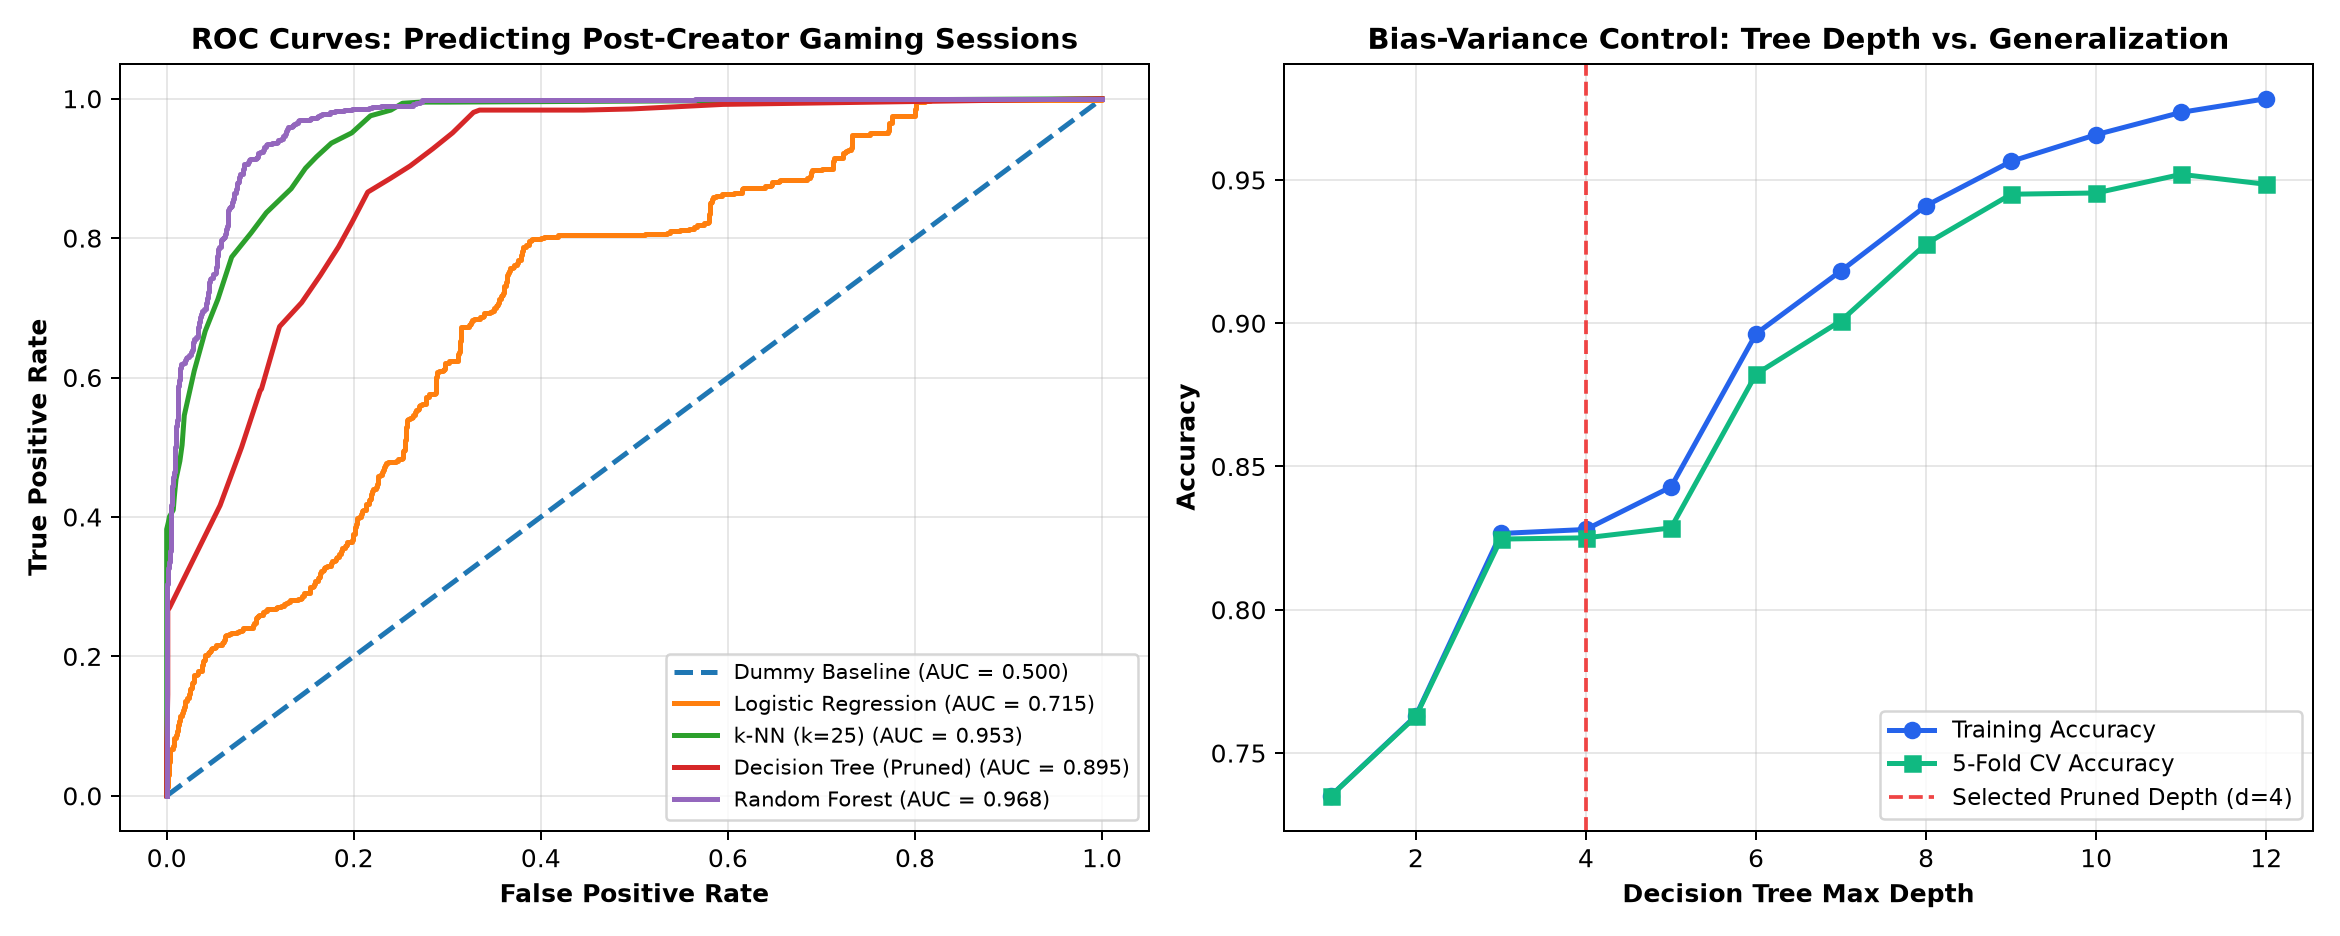

In [2]:
# 1. TASK A: CLIP-SESSION BEHAVIORAL REGIME CLASSIFICATION (N = 2,310)
clips_ml = pd.read_csv("data/processed/ml_clip_session_features.csv")
drop_clip_cols = [c for c in ["filename", "timestamp", "is_post_creator"] if c in clips_ml.columns]
X_clip = clips_ml.drop(columns=drop_clip_cols)
y_clip = clips_ml["is_post_creator"]

clip_models = get_classifiers(k_neighbors=25)  # k < sqrt(2310) ~= 48
clip_results = evaluate_models(X_clip, y_clip, clip_models)
print("=== TASK A: CREATOR VS. POST-CREATOR CLIP SESSION CLASSIFICATION (5-FOLD CV) ===")
print(clip_results.to_string(index=False))

# Depth Pruning Curve (Bias-Variance Trade-off) + ROC Curves
depths = range(1, 13)
train_accs, cv_accs = [], []
for d in depths:
    dt = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42)
    res_d = cross_validate(dt, X_clip, y_clip, cv=CV, scoring="accuracy", return_train_score=True)
    train_accs.append(res_d["train_score"].mean())
    cv_accs.append(res_d["test_score"].mean())

fig = Figure(figsize=(13, 5.2))
ax1, ax2 = fig.subplots(1, 2)

# Left panel: ROC Curves via out-of-fold probabilities
for name, clf in clip_models.items():
    y_prob = cross_val_predict(clf, X_clip, y_clip, cv=CV, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y_clip, y_prob)
    roc_auc = auc(fpr, tpr)
    ls = "--" if "Dummy" in name else "-"
    ax1.plot(fpr, tpr, linestyle=ls, linewidth=2, label=f"{name} (AUC = {roc_auc:.3f})")

ax1.set_xlabel("False Positive Rate", fontweight="bold")
ax1.set_ylabel("True Positive Rate", fontweight="bold")
ax1.set_title("ROC Curves: Predicting Post-Creator Gaming Sessions", fontsize=11.5, fontweight="bold")
ax1.legend(loc="lower right", fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Right panel: Decision Tree Pruning Curve
ax2.plot(list(depths), train_accs, marker="o", color="#2563eb", linewidth=2, label="Training Accuracy")
ax2.plot(list(depths), cv_accs, marker="s", color="#10b981", linewidth=2, label="5-Fold CV Accuracy")
ax2.axvline(4, color="#ef4444", linestyle="--", label="Selected Pruned Depth (d=4)")
ax2.set_xlabel("Decision Tree Max Depth", fontweight="bold")
ax2.set_ylabel("Accuracy", fontweight="bold")
ax2.set_title("Bias-Variance Control: Tree Depth vs. Generalization", fontsize=11.5, fontweight="bold")
ax2.legend(loc="lower right", fontsize=9)
ax2.grid(True, alpha=0.3)

save_and_show(fig, "04_ml_regime_roc_and_pruning.png")

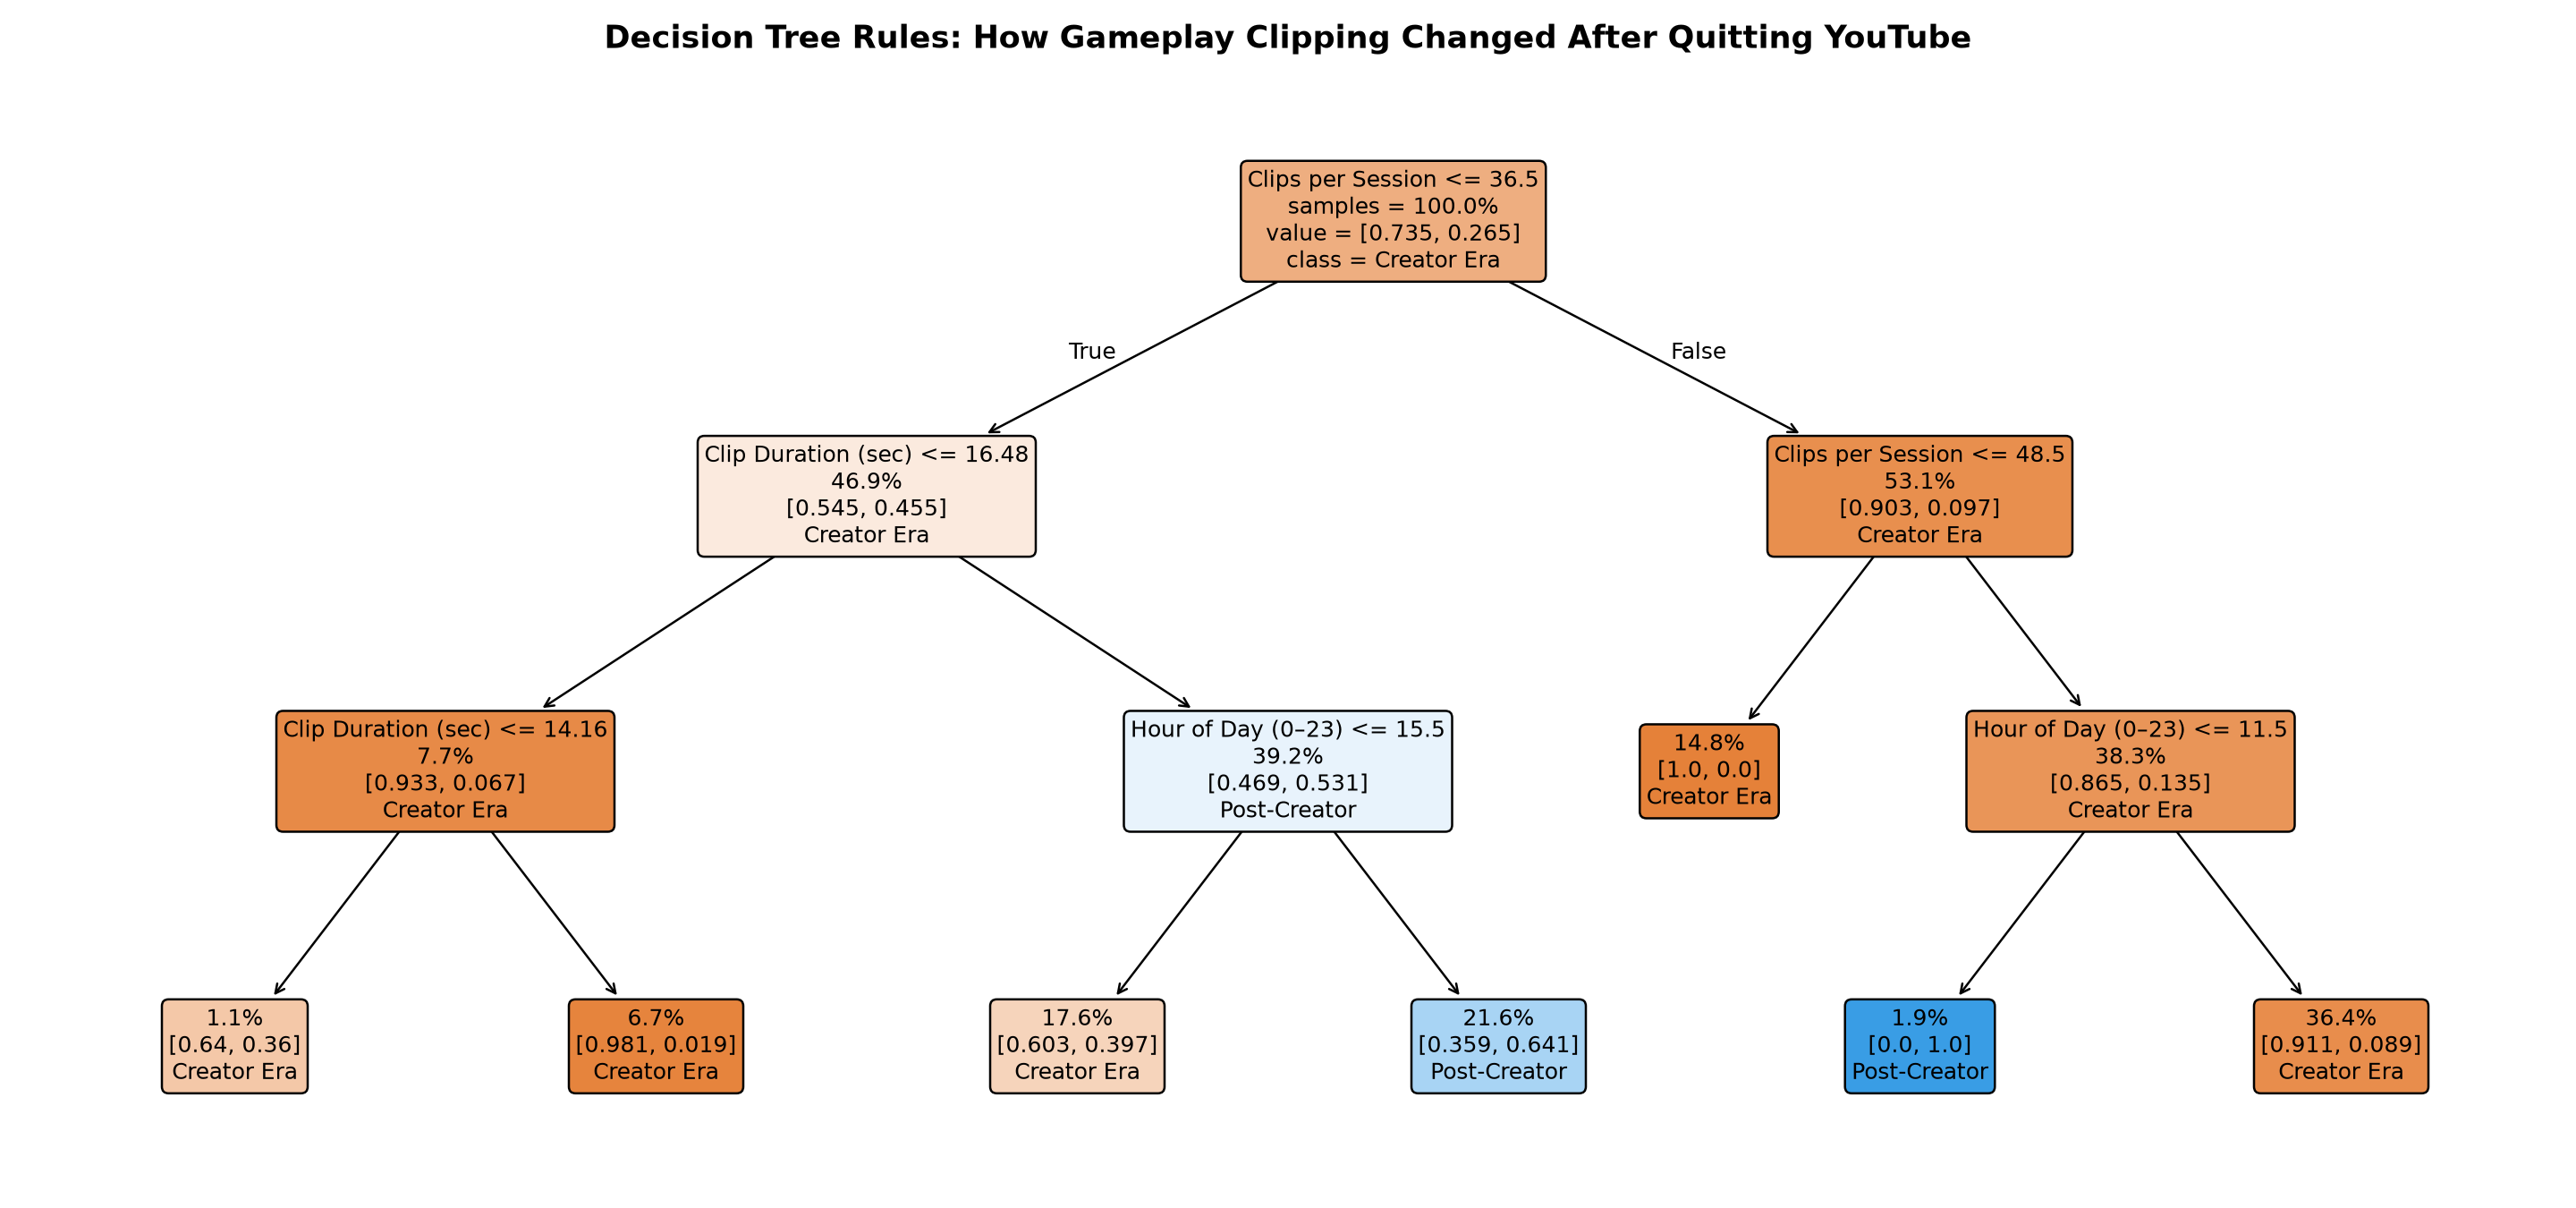

In [3]:
# 2. INTERPRETABLE 3-LEVEL DECISION TREE RULES (INFORMATION GAIN)
feature_label_map = {
    "hour": "Hour of Day (0–23)",
    "session_clip_count": "Clips per Session",
    "duration_sec": "Clip Duration (sec)",
    "is_weekend": "Weekend Session",
    "capped_gap_min": "Minutes Between Clips",
}
interpretable_cols = [c for c in feature_label_map if c in X_clip.columns]
readable_names = [feature_label_map[c] for c in interpretable_cols]

tree_vis = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=25, random_state=42)
tree_vis.fit(X_clip[interpretable_cols], y_clip)

fig = Figure(figsize=(16, 7.5))
FigureCanvasAgg(fig)
ax = fig.subplots()
plot_tree(
    tree_vis,
    feature_names=readable_names,
    class_names=["Creator Era", "Post-Creator"],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    label="root",
    fontsize=10,
    ax=ax,
)
ax.set_title("Decision Tree Rules: How Gameplay Clipping Changed After Quitting YouTube", fontsize=14, fontweight="bold", pad=16)
save_and_show(fig, "05_interpretable_regime_tree.png")

In [4]:
# 3. TASK B: YOUTUBE VIDEO BREAKOUT PREDICTION (N = 124)
yt_ml = pd.read_csv("data/processed/ml_youtube_features.csv")
X_yt = yt_ml.drop(columns=["Video title", "Views", "Thumbnail click-through rate (%)", "is_breakout_video"])
y_yt = yt_ml["is_breakout_video"]

yt_models = get_classifiers(k_neighbors=7)  # k < sqrt(124) ~= 11
yt_models["Decision Tree (Pruned)"] = DecisionTreeClassifier(criterion="entropy", max_depth=3, min_samples_leaf=5, random_state=42)
yt_results = evaluate_models(X_yt, y_yt, yt_models)

print("\n=== TASK B: YOUTUBE BREAKOUT VIDEO (>=100 VIEWS) CLASSIFICATION (5-FOLD CV) ===")
print(yt_results.to_string(index=False))


=== TASK B: YOUTUBE BREAKOUT VIDEO (>=100 VIEWS) CLASSIFICATION (5-FOLD CV) ===
                 Model  Accuracy  Precision  Recall    F1  ROC_AUC
        Dummy Baseline     0.524      0.000   0.000 0.000    0.500
   Logistic Regression     0.695      0.704   0.615 0.645    0.753
            k-NN (k=7)     0.710      0.738   0.632 0.662    0.802
Decision Tree (Pruned)     0.702      0.740   0.667 0.667    0.776
         Random Forest     0.687      0.683   0.667 0.657    0.765



=== TASK C: COUNTERFACTUAL CHANNEL GROWTH (PRE-BREAK RIDGE REGRESSION) ===
Pre-Break Training Months (Nov 2019 - Dec 2020): 14 | In-Sample RMSE: 118.7 views/mo
Actual Cumulative Views (Nov 2023):         16,761
Counterfactual Unburned Views (Nov 2023):   35,207
Estimated Burnout Opportunity Cost:         +18,446 views (+110.1%)


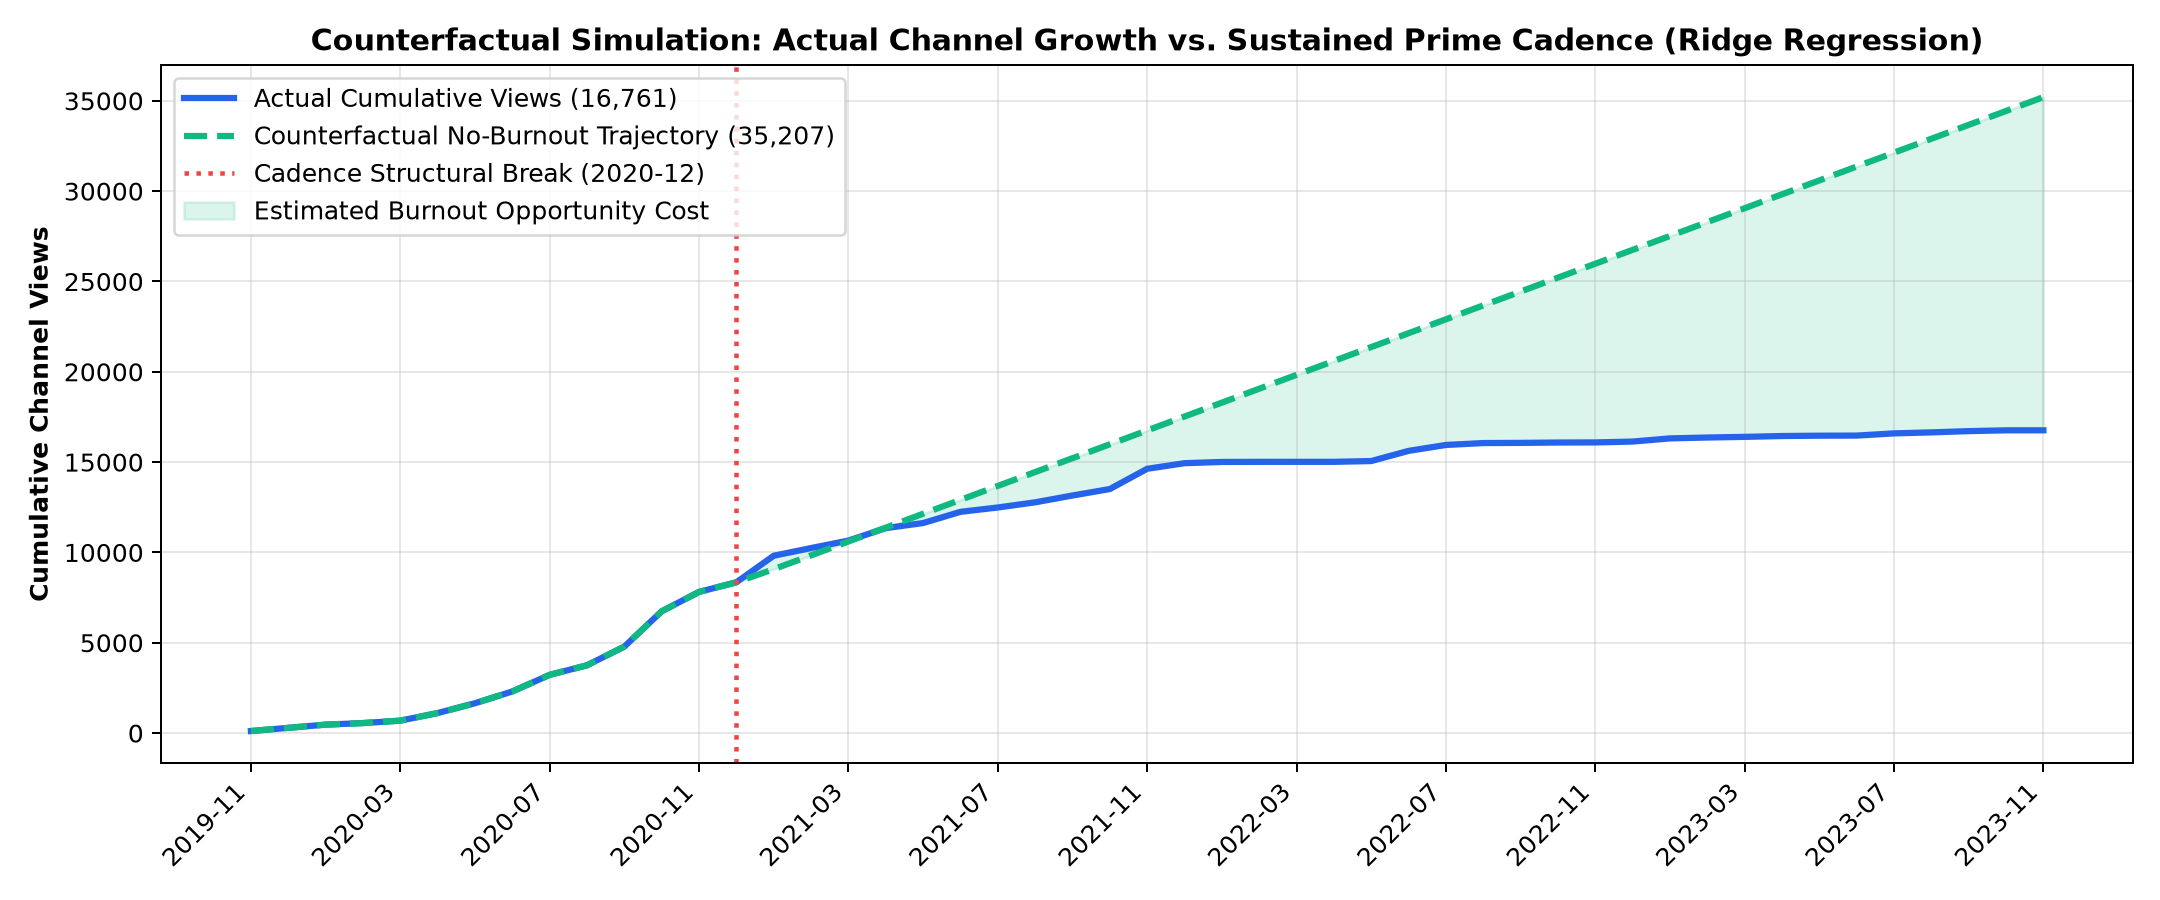

In [5]:
# 4. TASK C: COUNTERFACTUAL "WHAT-IF" BURNOUT SIMULATION (RIDGE REGRESSION)
cf = pd.read_csv("data/processed/ml_monthly_burnout.csv")
train_cf = cf[cf["is_pre_break"] == 1].copy()

reg_features = ["uploads", "highlight_share", "lag1_uploads", "lag1_views"]
ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge_pipe.fit(train_cf[reg_features], train_cf["views"])

in_sample_rmse = np.sqrt(mean_squared_error(train_cf["views"], ridge_pipe.predict(train_cf[reg_features])))
print(f"\n=== TASK C: COUNTERFACTUAL CHANNEL GROWTH (PRE-BREAK RIDGE REGRESSION) ===")
print(f"Pre-Break Training Months (Nov 2019 - Dec 2020): {len(train_cf)} | In-Sample RMSE: {in_sample_rmse:.1f} views/mo")

# Simulate unburned trajectory from Jan 2021 onward (8 uploads/mo, 30% edited highlights)
sim_views = []
prev_views = float(train_cf["views"].iloc[-1])
prev_uploads = float(train_cf["uploads"].iloc[-1])

for _, row in cf.iterrows():
    if row["is_pre_break"] == 1:
        sim_views.append(float(row["views"]))
    else:
        x_step = pd.DataFrame([{
            "uploads": 8.0,
            "highlight_share": 0.30,
            "lag1_uploads": prev_uploads,
            "lag1_views": prev_views,
        }])
        pred = max(0.0, float(ridge_pipe.predict(x_step)[0]))
        sim_views.append(pred)
        prev_views = pred
        prev_uploads = 8.0

cf["counterfactual_views"] = sim_views
cf["actual_cum_views"] = cf["views"].cumsum()
cf["counterfactual_cum_views"] = cf["counterfactual_views"].cumsum()

actual_total = cf["actual_cum_views"].iloc[-1]
cf_total = cf["counterfactual_cum_views"].iloc[-1]
burnout_cost = cf_total - actual_total
print(f"Actual Cumulative Views (Nov 2023):         {actual_total:,.0f}")
print(f"Counterfactual Unburned Views (Nov 2023):   {cf_total:,.0f}")
print(f"Estimated Burnout Opportunity Cost:         +{burnout_cost:,.0f} views (+{burnout_cost / actual_total:.1%})")

fig = Figure(figsize=(12, 5))
ax = fig.subplots()
ax.plot(cf["month"], cf["actual_cum_views"], color="#2563eb", linewidth=2.5, label=f"Actual Cumulative Views ({actual_total:,.0f})")
ax.plot(cf["month"], cf["counterfactual_cum_views"], color="#10b981", linestyle="--", linewidth=2.5, label=f"Counterfactual No-Burnout Trajectory ({cf_total:,.0f})")
ax.axvline("2020-12", color="#ef4444", linestyle=":", linewidth=1.8, label="Cadence Structural Break (2020-12)")
ax.fill_between(cf["month"], cf["actual_cum_views"], cf["counterfactual_cum_views"], where=(cf["month"] >= "2020-12"), color="#10b981", alpha=0.15, label="Estimated Burnout Opportunity Cost")

tick_idx = list(range(0, len(cf), 4))
ax.set_xticks(tick_idx)
ax.set_xticklabels([cf["month"].iloc[i] for i in tick_idx], rotation=45, ha="right")
ax.set_ylabel("Cumulative Channel Views", fontweight="bold")
ax.set_title("Counterfactual Simulation: Actual Channel Growth vs. Sustained Prime Cadence (Ridge Regression)", fontsize=12, fontweight="bold")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
save_and_show(fig, "06_counterfactual_channel_growth.png")